#### Comprobamos y tomamos decisiones antes del EDA. Los datos llegan de src/. Documentamos también las anomalías y justificamos la decisión tomada en cada momento.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd

from src.datos import cargar_csv, cargar_datos, consultar

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (8, 4)

## 1.

In [2]:
tablas = ["jugadores_acb", "temporadas_acb", "temporadas_acb_club", "jugadores_feb",
          "temporadas_feb", "trayectorias_feb", "emparejamiento", "dataset_modelo"]
pd.DataFrame({t: [len(cargar_datos(t))] for t in tablas}, index=["filas"]).T

,filas
jugadores_acb,2284
temporadas_acb,7272
temporadas_acb_club,7401
jugadores_feb,3115
temporadas_feb,8136
trayectorias_feb,17304
emparejamiento,756
dataset_modelo,7452


## 2. ACB

#### La temporada 26/27 tiene solo 4 partidos, por lo que la eliminamos de la "ecuación"

In [3]:
temporadas_acb = cargar_datos("temporadas_acb")
partidos_por_temporada = temporadas_acb.groupby("anio")["partidos"].median()
partidos_por_temporada.tail(6)

anio
2021    26.5
2022    27.0
2023    27.0
2024    27.5
2025    26.5
2026     3.0
Name: partidos, dtype: float64

* Vemos que la mediana de partidos por jugador es de 26 y 28 partidos exceptuando la 2026 ya que, como hemos dicho, acaba de empezar. Por esto mismo, la excluimos.

#### Victorias + derrotas (comprobación de scraping)

In [4]:
por_club = cargar_datos("temporadas_acb_club")
descuadre = por_club[por_club["victorias"] + por_club["derrotas"] != por_club["partidos"]]
print(f"Filas con descuadre: {len(descuadre)} de {len(por_club)}")
descuadre.groupby(["temporada", "club"]).size()

Filas con descuadre: 41 de 7401


temporada  club                   
16-17      RETAbet Bilbao Basket      10
           Real Betis Energía Plus     9
19-20      BAXI Manresa               11
           Coosur Real Betis          10
           Real Madrid                 1
dtype: int64

* Confirmamos que el scraper funciona

#### Columnas de las que dudamos

In [5]:
publicado = (por_club.groupby("temporada")["mas_menos"].apply(lambda s: (s.fillna(0) != 0).mean()))
publicado.tail(25).round(2)

temporada
14-15    0.98
15-16    0.98
16-17    0.99
17-18    0.97
18-19    0.98
19-20    0.97
20-21    0.98
21-22    0.97
22-23    0.99
23-24    0.98
24-25    0.99
25-26    0.98
26-27    0.98
88-89    0.00
89-90    0.00
90-91    0.00
91-92    0.00
92-93    0.00
93-94    0.00
94-95    0.00
95-96    0.00
96-97    0.00
97-98    0.00
98-99    0.00
99-00    0.00
Name: mas_menos, dtype: float64

In [6]:
por_club["titular"].describe()

count    7401.000000
mean        0.392379
std         0.344566
min         0.000000
25%         0.100000
50%         0.300000
75%         0.700000
max         1.000000
Name: titular, dtype: float64

In [7]:
por_club_jugados = por_club[por_club["partidos"] > 0]

publicado = (por_club_jugados.groupby("anio")["mas_menos"]
             .apply(lambda s: (s.fillna(0) != 0).mean()))
publicado.round(2)

anio
1988    0.00
1989    0.00
1990    0.00
1991    0.00
1992    0.00
1993    0.00
1994    0.00
1995    0.00
1996    0.00
1997    0.00
1998    0.00
1999    0.00
2000    0.00
2001    0.00
2002    0.00
2003    0.00
2004    0.00
2005    0.00
2006    0.00
2007    0.00
2008    0.00
2009    0.00
2010    0.00
2011    0.96
2012    0.99
2013    0.99
2014    0.98
2015    0.98
2016    0.99
2017    0.97
2018    0.98
2019    0.97
2020    0.98
2021    0.97
2022    0.99
2023    0.98
2024    0.99
2025    0.98
2026    0.98
Name: mas_menos, dtype: float64

In [8]:
print("Primer año con +/- publicado:", publicado[publicado > 0.5].index.min())
publicado.loc[2000:2015].round(2)

Primer año con +/- publicado: 2011


anio
2000    0.00
2001    0.00
2002    0.00
2003    0.00
2004    0.00
2005    0.00
2006    0.00
2007    0.00
2008    0.00
2009    0.00
2010    0.00
2011    0.96
2012    0.99
2013    0.99
2014    0.98
2015    0.98
Name: mas_menos, dtype: float64

* La titularidad del jugador va de __0__ a __1__ y no se empieza a contar desde la temporada __2011/2012__. 

#### "Problema" con las licencias

Creo que la categoría JFL es el sustituto de los jugadores con la etiqueta ESP.

In [9]:
jugadores_acb = cargar_datos("jugadores_acb")
ultima = temporadas_acb.groupby("id_acb")["anio"].max().rename("ultima_temporada")
licencias = jugadores_acb.set_index("id_acb").join(ultima)
licencias["periodo"] = pd.cut(licencias["ultima_temporada"], [0, 2010, 3000],
                              labels=["hasta 2010-11", "desde 2011-12"])
pd.crosstab(licencias["licencia"], licencias["periodo"], margins=True)

periodo,hasta 2010-11,desde 2011-12,All
licencia,,,
COT,1,180,181
ESP,133,0,133
EUR,119,500,619
EUR-F,76,194,270
EXT,136,422,558
JFL,5,514,519
JK,4,0,4
All,474,1810,2284


In [10]:
licencias[licencias["licencia"] == "JK"][["slug", "nacionalidad", "ultima_temporada"]]

,slug,nacionalidad,ultima_temporada
id_acb,,,
20201674,anthony-stacey,España,2006
20201837,william-mcdonald,España,2010
20201839,olatz-sarasola,España,2008
20201949,howard-brown,España,2006


* Confirmamos que los jugadores con etiqueta __JFL__ con sustitusod de __ESP__. Los __JK__ son extranjeros nacionalizados españoles. 

#### Licencia o nacionalidad?

In [11]:
pd.crosstab(jugadores_acb["licencia"], jugadores_acb["es_espanol"].map({1: "española", 0: "otra"}))

es_espanol,española,otra
licencia,,
COT,0,181
ESP,132,1
EUR,20,599
EUR-F,0,270
EXT,2,556
JFL,396,123
JK,4,0


* Tomamos la __licencia__ para tomar la nacionalidad de los jugadores ya que es más exacto.

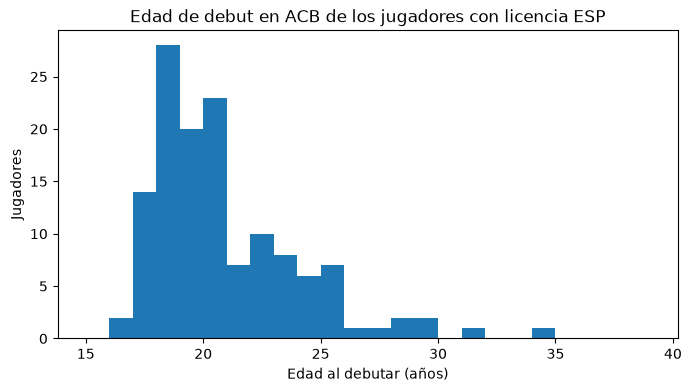

ESP que debutan con 24 años o más: 21 de 133


In [12]:
debut = cargar_datos("v_debut_acb").merge(jugadores_acb[["id_acb", "anio_nacimiento"]], on="id_acb")
debut["edad_debut"] = debut["debut"] - debut["anio_nacimiento"]
esp = debut[debut["licencia"] == "ESP"]
fig, ax = plt.subplots()
esp["edad_debut"].plot.hist(bins=range(15, 40), ax=ax)
ax.set(title="Edad de debut en ACB de los jugadores con licencia ESP",
       xlabel="Edad al debutar (años)", ylabel="Jugadores")
plt.show()
print(f"ESP que debutan con 24 años o más: {(esp['edad_debut'] >= 24).sum()} de {len(esp)}")

In [13]:
tardios = esp[esp["edad_debut"] >= 24]
emparejamiento = cargar_datos("emparejamiento")
print(f"Tardíos con pasado en la FEB: {tardios['id_acb'].isin(emparejamiento['id_acb']).sum()} de {len(tardios)}")

Tardíos con pasado en la FEB: 16 de 21


* Demostramos que la mayoría de los jugadores con licencia con __ESP/JFL__ debutan en la máxima categoría con edades entre __18 y 21 años__. De los __21 que debutaron con 24 o más, 15 jugaron en FEB__.

## 3. FEB

#### Comprobamos que los rankings no listan los "0".

In [14]:
rankings = cargar_csv("feb_rankings.csv")
conteo = rankings[~rankings["solo_nacionales"] & rankings["total"].notna()]
conteo.groupby("estadistica")["total"].min().sort_values()

estadistica
Valoración            -30.000000
Asistencias             1.000000
Balones recuperados     1.000000
Balones perdidos        1.000000
Rebotes Ofensivos       1.000000
Rebotes Defensivos      1.000000
Tapones a favor         1.000000
Puntos                  1.000000
Minutos jugados        15.833333
Name: total, dtype: float64

In [15]:
print("Valoraciones exactamente 0:", (conteo.loc[conteo["estadistica"] == "Valoración", "total"] == 0).sum())

Valoraciones exactamente 0: 0


* Efectivamente. __Feb no lista "0"__. No lista a jugadores con menos de esto. LA valoración puede ser también negativa pero 0 exactos como tal, no aparecen.

#### Total de las fichas

In [16]:
from src.limpieza_feb import construir_temporadas, integrar_totales

totales = cargar_csv("feb_totales.csv")
solo_rankings = construir_temporadas(rankings)
completada, resumen = integrar_totales(solo_rankings, totales)
print({k: v for k, v in resumen.items() if k != "fase_elegida"})
print("Fase de la ficha que coincidió:", resumen["fase_elegida"])

faltan = pd.DataFrame({
    "solo rankings": [solo_rankings[f"{t}_falta"].mean() for t in ["t2", "t3", "tl"]],
    "con fichas": [completada[f"{t}_falta"].mean() for t in ["t2", "t3", "tl"]],
}, index=["tiros de 2", "triples", "tiros libres"])
(100 * faltan).round(1)

{'filas': 8136, 'con_ficha': 8136, 'usadas': 7960, 'descartadas_por_no_coincidir': 176}
Fase de la ficha que coincidió: {'LR': 7300, '1ª': 315, 'todas': 287, '2ª': 45, 'R2': 13}


,solo rankings,con fichas
tiros de 2,27.0,0.5
triples,30.8,0.7
tiros libres,65.5,1.2


* Todo0s los tiros: de 2, 3  y TL entran como variables ya que se usaron 7960 de 8136 filas

In [17]:
sin_tiro = completada[completada["t2_falta"] == 1]
sin_tiro.groupby(["competicion", "temporada"]).size().sort_values(ascending=False).head(10)

competicion  temporada
segunda_feb  2009         19
primera_feb  2020         13
segunda_feb  2018          7
dtype: int64

* 39 filas de la FEB con 0 tiros de 2. (Segunda FEB2009, Primera FEB2020, Segunda FEB2018)

#### Descartamos lguna fila?

In [18]:
con_ficha = solo_rankings.merge(totales[["id_feb", "competicion", "temporada"]].drop_duplicates(),
                                on=["id_feb", "competicion", "temporada"])
descartadas = con_ficha.merge(completada[completada["faltas_recibidas"].isna()][["id_feb", "competicion", "temporada"]],
                              on=["id_feb", "competicion", "temporada"])
descartadas.groupby(["competicion", "temporada"]).size().sort_values(ascending=False).head(10)

competicion  temporada
segunda_feb  2009         76
primera_feb  2020         58
segunda_feb  2018         42
dtype: int64

In [19]:
total = solo_rankings.groupby(["competicion", "temporada"]).size()
pd.DataFrame({"descartadas": descartadas.groupby(["competicion", "temporada"]).size(),
              "total": total}).dropna()

descartadas  total
competicion temporada                    
primera_feb 2020              58.0    210
segunda_feb 2009              76.0    221
            2018              42.0    265

* 176 filas no se completaron. (temporadas mencionadas antes). No descartamos ninguna fila, ya que estos datos nos pueden indicar que se han tomado datos de alguna fase adicional (alguna fase de ascenso)

#### Liga U.

Se empezó con esta liga hace 1 año, por lo que habrán pocos datos

In [20]:
totales[totales["competicion"] == "liga_u"]["fase"].fillna("(total)").value_counts()

fase
LR         178
(total)    178
2F         172
PO         118
34          22
Name: count, dtype: int64

* Se excluye del entrenamiento ya que con una temporada y sin haber llegado a la ACB, no se pueden tomar. Seguramente se use como ranking descriptivo de jóvenes. Los 178 jugadores tienen fase regular y la mayoría segunda fase y playoffs.

#### Jugadores con fichas - sin temporada

In [21]:
jugadores_feb = cargar_datos("jugadores_feb")
temporadas_feb = cargar_datos("temporadas_feb")
sobrantes = jugadores_feb[~jugadores_feb["id_feb"].isin(temporadas_feb["id_feb"])]
sobrantes

,id_feb,nombre,anio_nacimiento,altura_cm,puesto,nacionalidad
15,2868750,NaN,1996,NaN,NaN,CANADA


In [22]:
rankings[rankings["id_feb"] == "2868750"][["competicion", "temporada", "estadistica", "total"]]

,competicion,temporada,estadistica,total


* De los datos que nos habíamos descargado, (3115 fichas) habían 3114 jugadores con temporadas, es decir, sobraba un jugador. Ya sabemos el ID del jugador aunque no nos afecte (temporadas)

#### Estadísticas 40 minutos vs. pocos

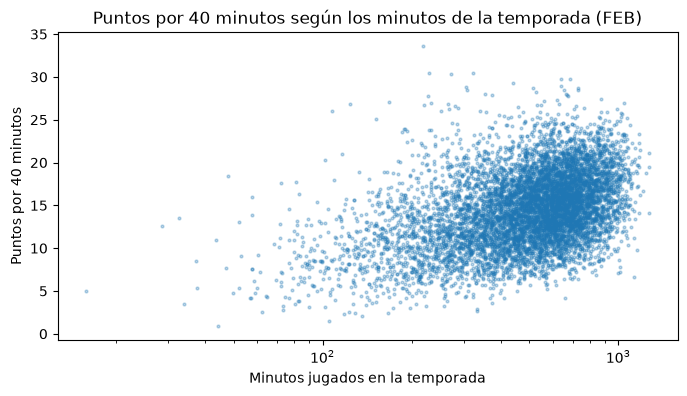

,count,mean,std
minutos,,,
"(0, 50]",11,8.3,5.1
"(50, 100]",98,8.5,3.4
"(100, 200]",452,10.7,4.2
"(200, 400]",1755,12.9,4.3
"(400, 10000]",5820,15.4,3.9


In [23]:
fig, ax = plt.subplots()
ax.scatter(temporadas_feb["minutos"], temporadas_feb["puntos_40"], s=4, alpha=0.3)
ax.set(title="Puntos por 40 minutos según los minutos de la temporada (FEB)",
       xlabel="Minutos jugados en la temporada", ylabel="Puntos por 40 minutos", xscale="log")
plt.show()

cortes = [0, 50, 100, 200, 400, 10_000]
temporadas_feb.groupby(pd.cut(temporadas_feb["minutos"], cortes))["puntos_40"].agg(["count", "mean", "std"]).round(1)

In [24]:
dataset = cargar_datos("dataset_modelo").dropna(subset=["se_asienta"])
dataset.groupby(pd.cut(dataset["minutos"], cortes))["se_asienta"].agg(["count", "sum"])

,count,sum
minutos,,
"(100, 200]",316,0.0
"(200, 400]",1301,20.0
"(400, 10000]",4499,285.0


* Se va a exigir un mínimo de 100 minutos en la temporada. Por debajo solo hay 75 filas y 1 de los 314 jugadores que se asientan. Los minutos serán una variable clave.

#### Licencias en FEB

In [25]:
emparejamiento = cargar_datos("emparejamiento")
nacional = (temporadas_feb.groupby("id_feb")["es_nacional_feb"].max().rename("nacional_feb").reset_index()
            .merge(emparejamiento, on="id_feb")
            .merge(jugadores_acb[["id_acb", "licencia"]], on="id_acb"))
pd.crosstab(nacional["licencia"], nacional["nacional_feb"].map({1: "nacional FEB", 0: "extranjero FEB"}))

nacional_feb,extranjero FEB,nacional FEB
licencia,,
COT,39,0
ESP,1,96
EUR,122,11
EUR-F,33,0
EXT,57,2
JFL,85,308
JK,2,0


In [26]:
jfl_extranjeros = nacional[(nacional["licencia"] == "JFL") & (nacional["nacional_feb"] == 0)]
jugadores_acb.set_index("id_acb").loc[jfl_extranjeros["id_acb"], "nacionalidad"].value_counts().head(10)

nacionalidad
Senegal        9
Letonia        7
Montenegro     5
Suecia         5
Chequia        4
Serbia         4
Eslovenia      4
Italia         3
Reino Unido    3
Francia        3
Name: count, dtype: int64

In [27]:
print("De los 84, con nacionalidad española:",
      (jugadores_acb.set_index("id_acb").loc[jfl_extranjeros["id_acb"], "nacionalidad"] == "España").sum())

De los 84, con nacionalidad española: 2


* En FEB no podemos usar el filtro "Nacional" para identificar JFL, ya que va por pasaporte y no por formación (84 JFL aparecen como extranjeros). Se usará como variable del modelo, pero no para buscar candidatos.

#### Trayectorias

In [28]:
trayectorias = cargar_datos("trayectorias_feb")
trayectorias.groupby("nivel")["categoria"].value_counts()

nivel             categoria     
leb_bronce        BRONCE             212
liga_u            LIGA U             153
primera_division  1ª División M.      11
primera_feb       LEB ORO           2158
                  ORO               1307
                  LEB               1104
                  PRIMERA FEB        614
segunda_feb       LEB PLATA         2509
                  PLATA             1118
                  SEGUNDA FEB        870
                  LEB 2              757
tercera_feb       EBA               3044
                  LIGA EBA          2745
                  TERCERA FEB        702
Name: count, dtype: int64

In [29]:
trayectorias_brutas = cargar_csv("feb_trayectorias.csv")
trayectorias_brutas[~trayectorias_brutas["categoria"].isin(trayectorias["categoria"].unique())]

,id_feb,temporada,categoria,club
416,883336,97/98,Liga Femenina,FEMENINO TRES CANTOS [FEMENINO TRES CANTOS]
418,883336,98/99,Liga Femenina,DEPORTIVO ENSINO [CD ENSINO UNIVERSIDADE]
1087,823055,97/98,Liga Femenina,DEPORTIVO ENSINO [CD ENSINO]
1089,823055,98/99,Liga Femenina,DEPORTIVO ENSINO [CD ENSINO UNIVERSIDADE]
1090,823055,99/00,Liga Femenina,DEPORTIVO ENSINO [C.D. ENSINO]
1817,347725,98/99,Liga Femenina,DEPORTIVO ENSINO [CD ENSINO UNIVERSIDADE]
1819,347725,99/00,Liga Femenina,DEPORTIVO ENSINO [C.D. ENSINO]
1852,970014,97/98,Liga Femenina,C.B. ISLAS CANARIAS [SANDRA GRAN CANARIA]
1892,1751519,97/98,Liga Femenina,CLUB BALONCESTO NAVARRA [CBN]
1893,1751519,98/99,Liga Femenina,C.B. ISLAS CANARIAS [SANDRA GRAN CANARIA]


* LAs categorías se unifican correctamente en sus niveles(Primera, Segunda y Tercera FEB, LEB Bronce y Liga U) y 11 filas de la PRimera División sin incluir: Juniors, Cadetes... 
* En Liga Femenina reflejan, seguramente, jugadores con un cargo antiguo e mal registrados. Se excluyen.

## FEB <-> ACB

#### Empajeramiento

In [30]:
print(emparejamiento["metodo"].value_counts())
dudosos = cargar_csv("emparejamiento_dudosos.csv", "processed")
dudosos

metodo
completo             736
nombre_parecido       16
nombre_y_apellido      4
Name: count, dtype: int64


,id_acb,id_feb,metodo,slug,anio_nacimiento,jugador
0,20204146,1322114,completo,alejandro-suarez,1993,"SUÁREZ CASTRO, ALEJANDRO"
1,20204146,2432573,completo,alejandro-suarez,1993,"SUAREZ MONTERO, MANUEL ALEJANDRO"
2,20210684,1321036,completo,pablo-perez,1997,"PÉREZ GARRIDO, PABLO"
3,20210684,1678003,completo,pablo-perez,1997,"PEREZ FERNANDEZ, PABLO"


In [31]:
debut = cargar_datos("v_debut_acb").set_index("id_acb")["debut"]
for _, fila in dudosos.iterrows():
    temporadas = temporadas_feb.loc[temporadas_feb["id_feb"] == fila["id_feb"], "temporada"]
    print(fila["slug"], fila["jugador"], "| debut ACB:", debut.get(fila["id_acb"]),
          "| temporadas FEB:", sorted(temporadas.unique()))

alejandro-suarez SUÁREZ CASTRO, ALEJANDRO | debut ACB: 2010 | temporadas FEB: [np.int64(2011), np.int64(2012), np.int64(2024)]
alejandro-suarez SUAREZ MONTERO, MANUEL ALEJANDRO | debut ACB: 2010 | temporadas FEB: [np.int64(2020)]
pablo-perez PÉREZ GARRIDO, PABLO | debut ACB: 2013 | temporadas FEB: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018)]
pablo-perez PEREZ FERNANDEZ, PABLO | debut ACB: 2013 | temporadas FEB: [np.int64(2020), np.int64(2021)]


In [32]:
emparejamiento[emparejamiento["metodo"] == "nombre_y_apellido"].merge(
    jugadores_feb[["id_feb", "nombre"]], on="id_feb").merge(
    jugadores_acb[["id_acb", "slug"]], on="id_acb")

,id_acb,id_feb,metodo,nombre,slug
0,20202004,1586127,nombre_y_apellido,"JAGLA, JAN HENDRICK LUKO",jan-hendrik-jagla
1,20202011,1509898,nombre_y_apellido,"EVANS, HESHIMU KENYATTA",heshimu-kenyata-evans
2,20202130,1478662,nombre_y_apellido,"BARBOUR, ANTWAIN LA'MAR",antwain-lamar-barbour
3,20209815,1816948,nombre_y_apellido,"WASHINGTON, DERON RCHAR",deron-rachard-washington


* 740 emparejados: 736 por nombre completo y 4 por nombre y primer apellido. Estos últimos 4 se revisaron a mano y son correctos.

#### Debutantes en ACB pasando por FEB

In [33]:
cobertura = cargar_datos("v_cobertura_feb")
cobertura = cobertura[cobertura["debut"].between(2006, 2025)]
cobertura.groupby("licencia")["tiene_pareja_feb"].agg(jugadores="size", con_pareja="mean").round(3)

,jugadores,con_pareja
licencia,,
COT,167,0.228
ESP,48,0.792
EUR,513,0.216
EUR-F,235,0.136
EXT,469,0.098
JFL,435,0.782
JK,1,1.000


In [34]:
primera_feb = temporadas_feb.groupby("id_feb")["temporada"].min()
cob = cobertura.merge(emparejamiento[["id_acb", "id_feb"]], on="id_acb", how="left")
cob["feb_antes"] = cob["id_feb"].map(primera_feb) <= cob["debut"]
cob.groupby("licencia")["feb_antes"].mean().round(3)

licencia
COT      0.186
ESP      0.375
EUR      0.140
EUR-F    0.068
EXT      0.081
JFL      0.441
JK       1.000
Name: feb_antes, dtype: float64

* El emparejamiento encuentra pareja en la FEB para el 76 % de los JFL y el 79 % de los ESP que debutaron en la ACB. El 24 % de JFL sin pareja puede deberse a que subieron de la cantera o pasaron solo por una división inferior o vienen de la NCAA o no se emparejaron.

#### Revisión manual

In [35]:
sin_pareja = (cobertura[(cobertura["licencia"] == "JFL") & (cobertura["tiene_pareja_feb"] == 0)
                        & cobertura["debut"].between(2008, 2022)]
              .merge(jugadores_acb[["id_acb", "slug", "anio_nacimiento"]], on="id_acb"))
sin_pareja.sample(min(20, len(sin_pareja)), random_state=0)[["slug", "anio_nacimiento", "debut"]]

,slug,anio_nacimiento,debut
48,aday-mara,2005,2022
74,adama-traore,2005,2022
59,tristan-tsalikis-vouktsevits,2003,2020
54,nahuel-del-val,2001,2020
34,jose-san-martin,1999,2015
26,santiago-yusta,1997,2013
68,amar-sylla,2001,2022
33,samba-ndiaye,1998,2015
45,bassala-bagayoko,2006,2020
69,angel-corpas,2004,2022


In [36]:
from src.emparejar import palabras, palabras_slug

muestra = sin_pareja.sample(min(20, len(sin_pareja)), random_state=0)
jugadores_feb["palabras"] = jugadores_feb["nombre"].map(palabras)

for _, f in muestra.iterrows():
    apellido = palabras_slug(f["slug"])[-1]
    candidatos = jugadores_feb[
        jugadores_feb["palabras"].map(lambda p: apellido in p)
        & jugadores_feb["anio_nacimiento"].between(f["anio_nacimiento"] - 1, f["anio_nacimiento"] + 1)]
    print(f"{f['slug']:25s} {f['anio_nacimiento']}  ->",
          list(candidatos["nombre"] + " (" + candidatos["anio_nacimiento"].astype(str) + ")") or "ninguno")

aday-mara                 2005  -> ninguno
adama-traore              2005  -> ['TRAORE, YOUSSOUF MAMBY (2006)']
tristan-tsalikis-vouktsevits 2003  -> ninguno
nahuel-del-val            2001  -> ['HARO VAL, ALEIX (2001)', 'REVILLA VAL, FERNANDO (2001)']
jose-san-martin           1999  -> ['MORENO MARTIN, VICTOR (1998)', 'CARRALERO MARTIN, JESUS (2000)', 'MARTIN TRENADO, JEREMY (1998)']
santiago-yusta            1997  -> ninguno
amar-sylla                2001  -> ninguno
samba-ndiaye              1998  -> ['NDIAYE, SERIGNE LAMINE BARA (1998)']
bassala-bagayoko          2006  -> ninguno
angel-corpas              2004  -> ninguno
vit-krejci                2000  -> ninguno
albert-pons               2001  -> ninguno
alberto-jodar             1991  -> ninguno
andriy-gritsak            2000  -> ninguno
mario-nakic               2001  -> ninguno
alejandro-suarez          1993  -> ['SUÁREZ CASTRO, ALEJANDRO (1993)', 'SUAREZ MONTERO, MANUEL ALEJANDRO (1993)']
juan-hernangomez          1995  -> nin

* Se revisaron a mano 20 JFL sin pareja. 3 eran fallos del cruce por variantes del nombre de pila. 13 no tenían candidato: nunca jugaron en Primera, Segunda ni Liga U, y entre ellos hay varios canteranos de clubes grandes (Porziņģis, Garuba, Juan Núñez)

## 5. Tabla modelo

#### Umbral objetivo

In [37]:
from src.dataset import construir

fichas = cargar_csv("feb_jugadores.csv")
ultima_completa = int(temporadas_acb["anio"].max()) - 1
temporadas_completas = temporadas_acb[temporadas_acb["anio"] <= ultima_completa]

filas = []
for partidos, minutos in [(10, 10), (15, 15), (20, 20), (15, 20)]:
    tabla = construir(temporadas_feb, fichas, temporadas_completas, emparejamiento, ultima_completa,
                      min_partidos=partidos, min_minutos=minutos)
    con_objetivo = tabla.dropna(subset=["se_asienta"])
    filas.append({"min_partidos": partidos, "min_minutos": minutos,
                  "positivos": int(con_objetivo["se_asienta"].sum()),
                  "tasa": round(con_objetivo["se_asienta"].astype(float).mean(), 3)})
pd.DataFrame(filas)

,min_partidos,min_minutos,positivos,tasa
0,10,10,454,0.077
1,15,15,305,0.050
2,20,20,169,0.027
3,15,20,175,0.028


* Revisamos si podemos seleccionar jugadores que juegan 10 minutos en 10 partidos

In [38]:
def asentados(p, m):
    return set(temporadas_completas.loc[(temporadas_completas["partidos"] >= p)
                                        & (temporadas_completas["minutos"] >= m), "id_acb"])

solo_10 = asentados(10, 10) - asentados(15, 15)
print(f"Cumplen 10/10 alguna vez pero nunca 15/15: {len(solo_10)} jugadores ACB")

Cumplen 10/10 alguna vez pero nunca 15/15: 326 jugadores ACB


* Con 15 partidos y 15 minutos hay unos 320 positivos. Se mantiene ese umbral porque equivale a un jugador de rotación en una temporada de 34 jornadas. Expectativa realista para un jugador que sube de la FEB. con 20/20 los positivos bajan a la mitad quedaría con unos 90. Por lo que 15/15 está bien y no 10/10

In [39]:
modelo = cargar_datos("dataset_modelo")
modelo.groupby("temporada")["se_asienta"].apply(lambda s: s.isna().mean()).tail(6).round(2)

temporada
2020    0.0
2021    0.0
2022    0.0
2023    1.0
2024    1.0
2025    1.0
Name: se_asienta, dtype: float64

* Las filas hasta 2022 tienen todas objetivo; las de 2023, 2024 y 2025 no tienen ninguna, porque su horizonte de 3 temporadas termina después de 2025/26. La última temporada ACB completa. Al corregirlo se quitaron 15 positivos (de 320 a 305), por lo que se entrena con las temporadas hasta 2022; las 1.336 filas de 2023-2025 son los candidatos actuales a los que la app aplicará el modelo.

## 6. Resumen de decisiones

* 7.452 filas de Primera y Segunda FEB. El plan es usar 6.116 para entrenar el modelo y dejar 1.336 filas el modelo.
Como hay tan pocos positivos y los datos están muy desbalanceados, usar accuracy para medir si va bien resulta complicado. Hay que tirar de PR-AUC y recall si no queremos que el modelo nos falle. Además, el subgrupo de nacionales (154) da de sobra para analizarlo por separado.